# Cross-Border Payments Analytics

**Question:** Where is the payout network losing reliability, speed and revenue, and what should each team do about it?

Data: ~120K synthetic real-time payouts (Jan to Sep 2026) from 40 member businesses across 12 corridors, paid out to mobile wallets and bank accounts. See `docs/data_dictionary.md` for every field and metric definition.

Steps: **1.** load clean data → **2.** headline KPIs → **3.** growth → **4.** reliability by corridor → **5.** incident detection → **6.** member health → **7.** treasury → **8.** speed → **9.** cost of failures → **10.** recommendations

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG = ROOT / "images"; IMG.mkdir(exist_ok=True)

con = duckdb.connect()
con.execute(f"""
CREATE VIEW transactions AS SELECT * FROM read_csv_auto('{ROOT/'data/clean/transactions_clean.csv.gz'}', timestampformat='%Y-%m-%d %H:%M:%S');
CREATE VIEW members  AS SELECT * FROM read_csv_auto('{ROOT/'data/raw/members.csv'}');
CREATE VIEW partners AS SELECT * FROM read_csv_auto('{ROOT/'data/raw/payout_partners.csv'}');
""")
sql = lambda name: con.execute((ROOT / 'sql' / f'{name}.sql').read_text()).df()
q = lambda text: con.execute(text).df()

# Chart style: thin marks, recessive grid, one highlight color against gray
BLUE, ORANGE, RED, GRAY, INK, INK2 = '#2a78d6', '#eb6834', '#e34948', '#c9c8c3', '#0b0b0b', '#52514e'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#d6d5d0',
    'axes.grid': True, 'grid.color': '#ebeae6', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.labelcolor': INK2,
    'xtick.color': INK2, 'ytick.color': INK2, 'font.size': 10, 'axes.titlesize': 12,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'figure.dpi': 110})
def save(fig, name):
    fig.tight_layout(); fig.savefig(IMG / f'{name}.png', dpi=150, bbox_inches='tight'); plt.show()

## 1. Data quality first
The raw extract had duplicates, messy status labels, test payouts and missing fees. `src/clean_data.py` fixes each one and logs it:

In [2]:
pd.read_csv(ROOT / 'data/clean/data_quality_report.csv')

,check,rows_affected,action
0,Rows in raw extract,120480,starting point
1,Exact duplicate rows,478,dropped
2,Duplicate transaction_id (different values),2,kept latest row
3,Status labels with wrong case or spaces,299,standardized
4,Unknown status values,0,dropped
5,Zero or negative send amounts,45,dropped as test records
6,Failure reason on non-failed payout,60,cleared
7,Failed payout missing a reason,0,set to 'Unknown'
8,Missing fee on completed payout,180,rebuilt from segment fee schedule
9,completed_at before created_at,0,dropped


## 2. Headline KPIs

In [3]:
sql('01_kpi_summary').T.rename(columns={0: 'value'})

,value
payouts,119955.00
volume_usd_m,29.69
avg_ticket_usd,247.51
success_rate_pct,96.69
failure_rate_pct,3.19
revenue_usd_k,365.30
take_rate_bps,123.00
median_processing_sec,34.60
active_members,40.00
corridors,12.00


## 3. Growth
Daily payouts grew every month. Revenue grew faster than payout count because larger bank and remittance tickets grew.

,month,payouts,payouts_per_day,volume_usd_m,revenue_usd_k,failure_rate_pct,daily_payouts_mom_pct,revenue_mom_pct
0,2026-01,11419,368.0,2.27,29.3,3.17,NaN,NaN
1,2026-02,10570,378.0,2.22,28.9,3.15,2.5,-1.3
2,2026-03,12322,397.0,2.97,36.4,3.17,5.3,25.7
3,2026-04,12317,411.0,3.02,37.1,2.93,3.3,1.9
4,2026-05,13604,439.0,3.42,41.8,2.96,6.9,12.7
5,2026-06,13760,459.0,3.47,42.0,3.79,4.5,0.5
6,2026-07,14957,482.0,4.00,48.6,3.19,5.2,15.8
7,2026-08,15394,497.0,4.04,49.3,3.20,2.9,1.5
8,2026-09,15612,520.0,4.28,51.9,3.13,4.8,5.2


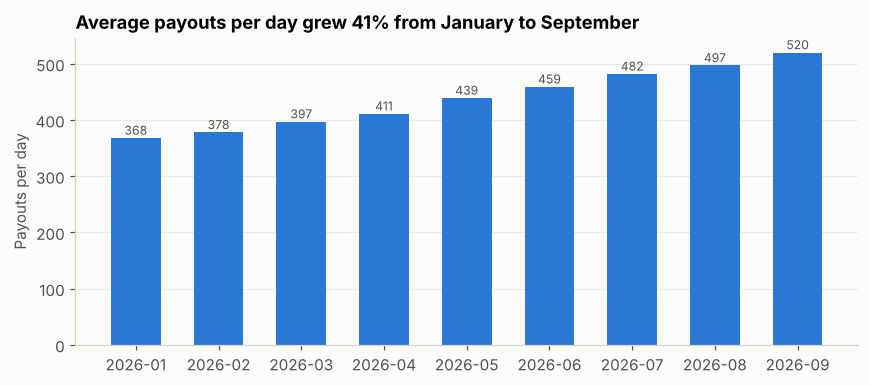

In [4]:
m = sql('02_monthly_trend'); display(m)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(m['month'], m['payouts_per_day'], color=BLUE, width=0.6)
for x, y in zip(m['month'], m['payouts_per_day']):
    ax.text(x, y + 6, f'{y:.0f}', ha='center', fontsize=8, color=INK2)
ax.set_title('Average payouts per day grew 41% from January to September')
ax.set_ylabel('Payouts per day'); ax.grid(axis='x', visible=False)
save(fig, '01_daily_payouts_trend')

## 4. Reliability by corridor
One corridor stands out: **UK → Nigeria bank payouts fail more than twice as often as the network**, and most of those failures are bad account details entered by the sender.

,corridor,payout_method,payouts,volume_usd_m,failure_rate_pct,p50_processing_sec,p90_processing_min,revenue_usd_k,worst_reliability_rank
0,GB-NG,Bank account,4489,1.00,8.04,1794.0,74.4,16.3,1
1,AE-PK,Mobile wallet,2993,0.94,4.85,6.0,0.3,12.3,2
2,AE-PK,Bank account,3034,0.97,4.42,113.0,746.1,12.8,3
3,GB-KE,Mobile wallet,5568,1.35,3.86,6.0,0.2,21.7,4
4,GB-KE,Bank account,994,0.23,3.63,93.0,4.0,3.7,5
5,HK-CN,Bank account,693,0.19,3.17,94.0,4.5,1.7,6
6,US-PH,Mobile wallet,20196,4.94,3.13,6.0,0.2,65.3,7
7,HK-CN,Mobile wallet,6206,1.91,3.08,6.0,0.2,17.2,8


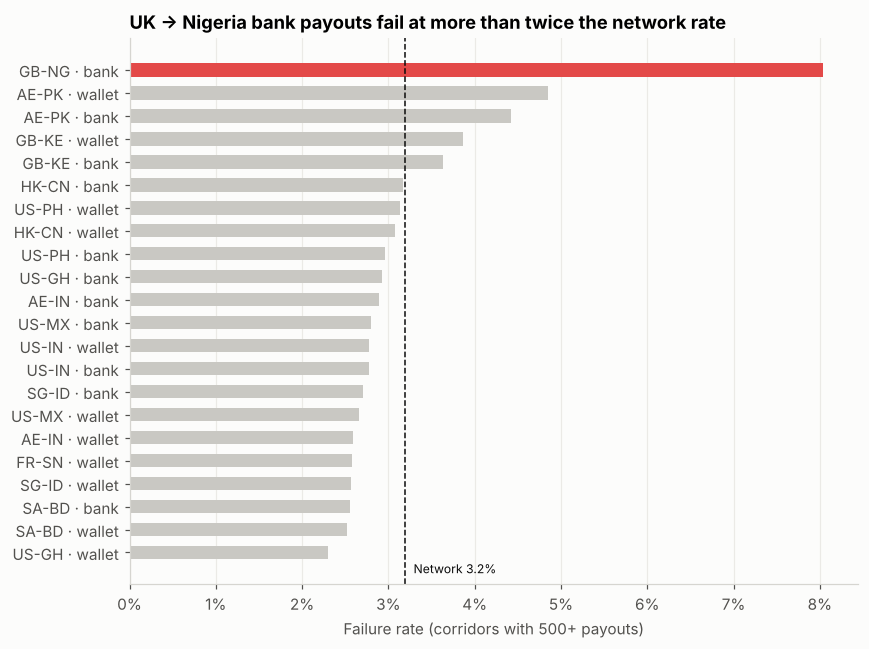

In [5]:
c = sql('03_corridor_performance'); display(c.head(8))
c['label'] = c['corridor'] + ' · ' + c['payout_method'].str.replace('Mobile wallet','wallet').str.replace('Bank account','bank')
c = c.sort_values('failure_rate_pct')
net = q("SELECT 100.0*SUM(is_failed)/SUM(is_final) AS r FROM transactions")['r'][0]
fig, ax = plt.subplots(figsize=(8, 6))
colors = [RED if r == c['failure_rate_pct'].max() else GRAY for r in c['failure_rate_pct']]
ax.barh(c['label'], c['failure_rate_pct'], color=colors, height=0.6)
ax.axvline(net, color=INK, lw=1, ls='--'); ax.text(net + 0.1, -0.9, f'Network {net:.1f}%', fontsize=8, color=INK)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title('UK → Nigeria bank payouts fail at more than twice the network rate')
ax.set_xlabel('Failure rate (corridors with 500+ payouts)'); ax.grid(axis='y', visible=False)
save(fig, '02_failure_rate_by_corridor')

In [6]:
sql('04_failure_reasons')

,corridor,top_failure_reason,failures,share_of_corridor_failures_pct
0,GB-NG,Invalid account details,280,75.5
1,AE-IN,Invalid account details,230,41.2
2,US-PH,Invalid account details,223,25.2
3,US-MX,Invalid account details,159,37.2
4,US-IN,Invalid account details,146,38.4
5,AE-PK,Compliance rejection,108,38.7
6,GB-KE,Insufficient prefunding,68,27.1
7,SG-ID,Invalid account details,62,28.7
8,HK-CN,Wallet not registered,44,20.7
9,US-GH,Invalid account details,29,29.9


## 5. Incident detection
This query compares each partner's daily failure rate with its own trailing 28-day average and flags days above 3×. It catches a **6-day outage at PH Wallet Partner A (June 8–13)** automatically, with no manual monitoring.

,partner_name,day,payouts,failures,failure_rate_pct,baseline_pct,times_baseline
0,PH Wallet Partner A,2026-06-08,46,15.0,32.6,2.4,13.4
1,PH Wallet Partner A,2026-06-09,33,10.0,30.3,3.3,9.1
2,PH Wallet Partner A,2026-06-10,45,12.0,26.7,4.1,6.5
3,PH Wallet Partner A,2026-06-11,40,16.0,40.0,4.9,8.1
4,PH Wallet Partner A,2026-06-12,55,18.0,32.7,6.2,5.3
5,PH Wallet Partner A,2026-06-13,46,13.0,28.3,7.7,3.7
6,IN Bank Partner A,2026-07-16,91,8.0,8.8,2.6,3.4


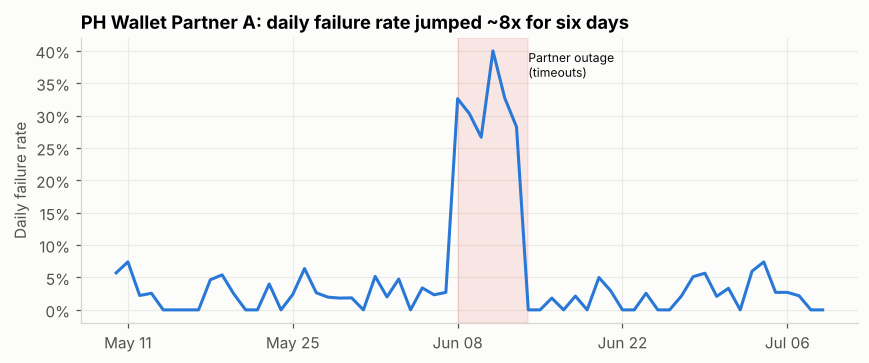

In [7]:
inc = sql('05_partner_incident_detection'); display(inc)
d = q("""
SELECT CAST(created_at AS DATE) AS day, 100.0*SUM(is_failed)/COUNT(*) AS fail_pct
FROM transactions JOIN partners USING (partner_id)
WHERE partner_name = 'PH Wallet Partner A' AND created_at BETWEEN '2026-05-10' AND '2026-07-10'
GROUP BY 1 ORDER BY 1""")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(d['day'], d['fail_pct'], color=BLUE, lw=2)
ax.axvspan(pd.Timestamp('2026-06-08'), pd.Timestamp('2026-06-13 23:59'), color=RED, alpha=0.12)
ax.text(pd.Timestamp('2026-06-14'), d['fail_pct'].max() * 0.9, 'Partner outage\n(timeouts)', fontsize=8, color=INK)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0, interval=2)); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_title('PH Wallet Partner A: daily failure rate jumped ~8x for six days')
ax.set_ylabel('Daily failure rate')
save(fig, '03_partner_outage')

## 6. Member health
One fintech member's failure rate jumped from under 3% to over 14% starting in July, driven by name mismatches and invalid account details. This looks like a change on **their** side (recipient data capture), not ours.

,member_name,segment,payouts,h1_failure_rate_pct,q3_failure_rate_pct,change_pts
0,DeltaPay,Fintech,1610,2.67,14.33,11.66
1,RidgeRemit,Remittance (MTO),557,2.98,4.52,1.55
2,TidalPay Gateway,PSP,4053,2.43,3.13,0.69
3,OrbitPay,Fintech,704,3.61,4.21,0.60
4,IvoryRide,Gig economy,3084,2.65,3.24,0.59
5,HavenPay,Fintech,5469,3.16,3.48,0.33
6,JunoRemit,Remittance (MTO),1883,2.76,3.04,0.28
7,SagePay,Fintech,4452,2.73,3.00,0.27
8,RallyRide,Gig economy,2633,3.67,3.93,0.27
9,PeakPay Gateway,PSP,5015,2.56,2.82,0.25


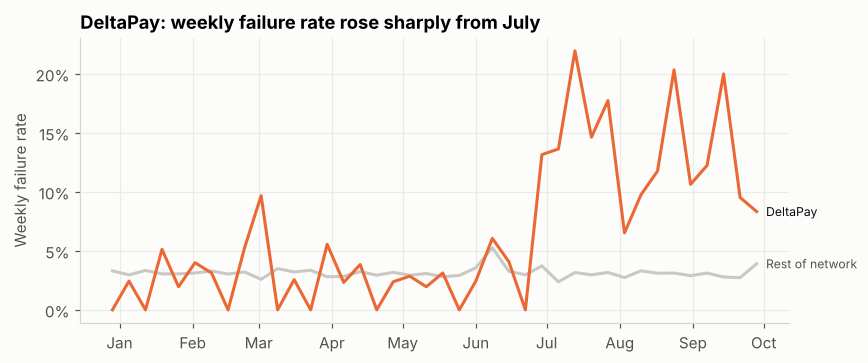

In [8]:
mh = sql('06_member_health'); display(mh)
worst = mh.iloc[0]['member_name']
w = q(f"""
SELECT DATE_TRUNC('week', created_at) AS wk,
       100.0*SUM(is_failed) FILTER (WHERE member_name = '{worst}') / SUM(is_final) FILTER (WHERE member_name = '{worst}') member_pct,
       100.0*SUM(is_failed) FILTER (WHERE member_name <> '{worst}') / SUM(is_final) FILTER (WHERE member_name <> '{worst}') network_pct
FROM transactions JOIN members USING (member_id)
GROUP BY 1 HAVING COUNT(*) FILTER (WHERE member_name = '{worst}') >= 20 ORDER BY 1""")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(w['wk'], w['network_pct'], color=GRAY, lw=2)
ax.plot(w['wk'], w['member_pct'], color=ORANGE, lw=2)
ax.text(w['wk'].iloc[-1] + pd.Timedelta(days=4), w['member_pct'].iloc[-1], worst, color=INK, fontsize=8, va='center')
ax.text(w['wk'].iloc[-1] + pd.Timedelta(days=4), w['network_pct'].iloc[-1], 'Rest of network', color=INK2, fontsize=8, va='center')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title(f'{worst}: weekly failure rate rose sharply from July')
ax.set_ylabel('Weekly failure rate')
save(fig, '04_member_failure_spike')

## 7. Treasury: month-end prefunding
Prefunding failures are rare everywhere except **Kenya in the last 3 days of each month**, when the prefunded balance runs out before it is topped up.

,receive_country,time_of_month,payouts,prefunding_failures,prefunding_failure_pct
0,KE,Last 3 days,767,64.0,8.34
1,IN,Rest of month,29564,17.0,0.06
2,PH,Rest of month,25533,9.0,0.04
3,ID,Rest of month,7327,7.0,0.10
4,KE,Rest of month,5795,4.0,0.07


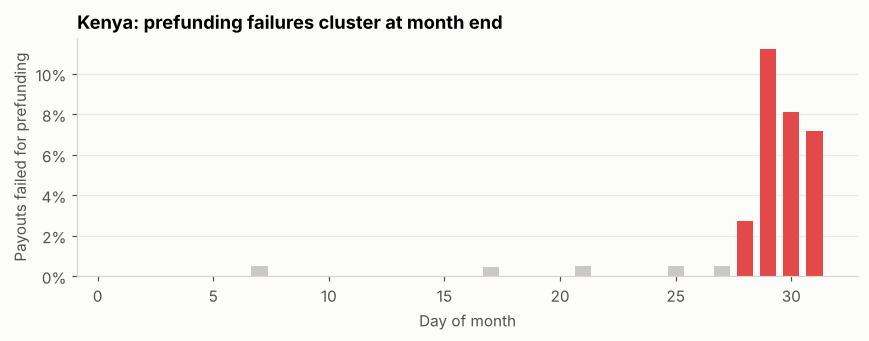

In [9]:
display(sql('07_month_end_prefunding').head(5))
k = q("""
SELECT DAY(created_at) AS dom,
       100.0*SUM(CASE WHEN failure_reason='Insufficient prefunding' THEN 1 ELSE 0 END)/COUNT(*) AS pct
FROM transactions WHERE receive_country = 'KE' GROUP BY 1 ORDER BY 1""")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(k['dom'], k['pct'], color=[RED if d >= 28 else GRAY for d in k['dom']], width=0.7)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title('Kenya: prefunding failures cluster at month end'); ax.set_xlabel('Day of month')
ax.set_ylabel('Payouts failed for prefunding'); ax.grid(axis='x', visible=False)
save(fig, '05_kenya_month_end_prefunding')

## 8. Speed: weekend bank payouts
Wallet payouts settle in seconds every day. Bank payouts to **India, Pakistan and Bangladesh** created on weekends wait hours for the next banking day.

,receive_country,weekend_payouts,weekday_p50_min,weekend_p50_min,weekend_over_1h_pct
0,BD,385,30.8,425.9,63.4
1,IN,7715,1.5,393.6,55.3
2,PK,776,1.6,390.7,57.1
3,NG,1020,30.1,29.4,16.5
4,KE,241,1.5,1.6,0.0
5,GH,337,1.5,1.6,0.0
6,CN,189,1.6,1.6,0.0
7,MX,3001,1.5,1.5,0.0
8,PH,2259,1.5,1.5,0.0
9,ID,884,1.5,1.5,0.0


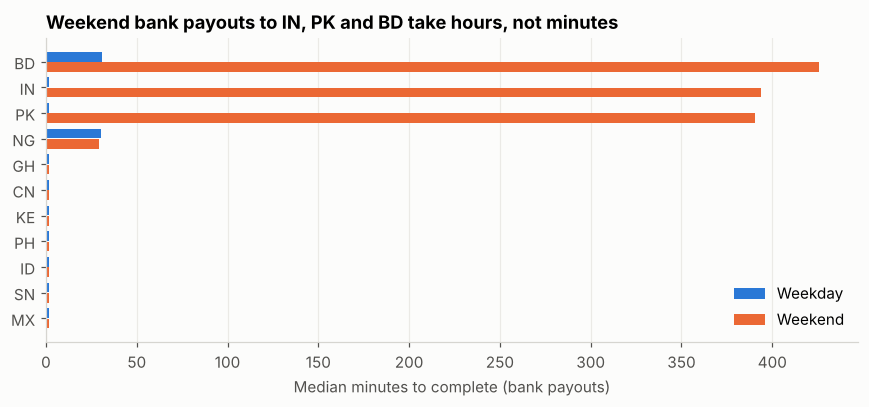

In [10]:
s = sql('08_weekend_bank_delays'); display(s)
s = s.sort_values('weekend_p50_min')
fig, ax = plt.subplots(figsize=(8, 3.8))
y = range(len(s))
ax.barh([i + 0.2 for i in y], s['weekday_p50_min'], height=0.38, color=BLUE, label='Weekday')
ax.barh([i - 0.2 for i in y], s['weekend_p50_min'], height=0.38, color=ORANGE, label='Weekend')
ax.set_yticks(list(y)); ax.set_yticklabels(s['receive_country'])
ax.set_xlabel('Median minutes to complete (bank payouts)'); ax.legend(frameon=False, loc='lower right')
ax.set_title('Weekend bank payouts to IN, PK and BD take hours, not minutes'); ax.grid(axis='y', visible=False)
save(fig, '06_weekend_bank_delays')

## 9. What failures cost

In [11]:
l = sql('10_revenue_lost_to_failures'); display(l)
print(f"Failed payout value: ${l['failed_volume_usd_k'].sum():,.0f}K | estimated direct revenue lost: ${l['est_revenue_lost_usd'].sum():,.0f}")

,failure_reason,failures,failed_volume_usd_k,est_revenue_lost_usd,share_of_lost_revenue_pct
0,Invalid account details,1273,307.0,4104.0,33.0
1,Name mismatch,646,169.0,2037.0,16.4
2,Partner timeout,434,107.0,1393.0,11.2
3,Recipient limit exceeded,421,176.0,1346.0,10.8
4,Compliance rejection,343,90.0,1201.0,9.7
5,Wallet not registered,314,88.0,1036.0,8.3
6,Other,272,68.0,867.0,7.0
7,Insufficient prefunding,122,27.0,442.0,3.6


Failed payout value: $1,032K | estimated direct revenue lost: $12,426


In [12]:
sql('09_revenue_concentration')

,rank,member_name,segment,revenue_usd_k,share_pct,cumulative_share_pct
0,1,ArcRemit,Remittance (MTO),41.4,11.3,11.3
1,2,SwiftBank,Bank,34.7,9.5,20.8
2,3,UmbraRemit,Remittance (MTO),24.2,6.6,27.4
3,4,WillowBank,Bank,22.3,6.1,33.5
4,5,MapleRemit,Remittance (MTO),18.6,5.1,38.6
5,6,HavenPay,Fintech,15.1,4.1,42.8
6,7,NimbusPay,Fintech,14.3,3.9,46.7
7,8,VelaPay,Fintech,14.1,3.9,50.6
8,9,SagePay,Fintech,12.5,3.4,54.0
9,10,HarborRemit,Remittance (MTO),12.1,3.3,57.3


## 10. Recommendations

| Finding | Owner | Action |
|---|---|---|
| UK → Nigeria bank payouts fail at 2x+ the network rate, mostly invalid account details | Product + Partnerships | Add account-number validation (bank name + account format check) before submission |
| PH Wallet Partner A outage went 6 days at ~30% failure | Operations | Turn query Q5 into a daily alert; auto-route to PH Wallet Partner B when a partner trips the 3x threshold |
| One fintech member's failures jumped ~5x from July | Account management | Share their failure breakdown, review recent changes to their recipient-capture flow |
| Kenya prefunding runs dry in the last 3 days of the month | Treasury | Top up Kenya balances before day 27 based on the month-end volume spike |
| Weekend bank payouts to IN, PK, BD take hours | Product + Sales | Set honest ETAs for weekend bank payouts; nudge members toward wallet payouts where available |
| Invalid account details + name mismatch are about half of lost revenue | Product | Pre-validation API for members (name and account checks before sending) |
